# 02 · Validación end-to-end de la fase 4 sobre vídeo independiente

**Objetivo:** validar el pipeline completo de tracking y clasificación de equipos sobre un vídeo no usado durante el desarrollo, con equipaciones distintas, y medir la precisión de la clasificación sobre una muestra aleatoria etiquetada manualmente.

**Pipeline:** detección + BoT-SORT → división de tracks por clase (histéresis) → cosido de tracklets → extracción del color dominante de camiseta → clasificación por modelo de mezcla equipación-césped → división de tracks por cambio sostenido de equipo → muestreo aleatorio para validación manual.

**Entrada:** un vídeo cualquiera (parámetro `VIDEO_IN`).

**Salida:** vídeo de validación, precisión de clasificación de equipo, y JSON de tracking+equipos para la fase 5.

**Importante:** reiniciar el kernel antes de ejecutar (el tracker acumula estado entre ejecuciones).

In [2]:
import json
import cv2
import numpy as np
from pathlib import Path
from collections import defaultdict
from ultralytics import YOLO

REPO_ROOT = Path("../..").resolve()

# ===== PARÁMETRO: vídeo a validar =====
VIDEO_IN = REPO_ROOT / "data" / "raw" / "test (27).mp4"
# ======================================

NOMBRE = VIDEO_IN.stem.replace(" ", "_").replace("(", "").replace(")", "")
detector = YOLO(str(REPO_ROOT / "models" / "best_v4.pt"))

# Config del tracker (se crea si no existe)
tracker_cfg = REPO_ROOT / "configs" / "botsort_custom.yaml"
tracker_cfg.parent.mkdir(parents=True, exist_ok=True)
if not tracker_cfg.exists():
    tracker_cfg.write_text("""tracker_type: botsort
track_high_thresh: 0.25
track_low_thresh: 0.1
new_track_thresh: 0.6
track_buffer: 120
match_thresh: 0.8
fuse_score: true
gmc_method: sparseOptFlow
proximity_thresh: 0.5
appearance_thresh: 0.25
with_reid: true
model: auto
""", encoding="utf-8")

print(f"Vídeo existe: {VIDEO_IN.exists()}")
print(f"Nombre limpio: {NOMBRE}")

Vídeo existe: True
Nombre limpio: test_27


## 1. Tracking con post-procesado (división por clase + cosido de tracklets)

In [3]:
# ---- Tracking crudo ----
frames_dets = []
results = detector.track(source=str(VIDEO_IN), stream=True, persist=True,
                         tracker=str(tracker_cfg), conf=0.25, imgsz=1280, verbose=False)
frame_idx = 0
for rd in results:
    dets = []
    if rd.boxes is not None and rd.boxes.id is not None:
        boxes = rd.boxes.xyxy.cpu().numpy()
        ids = rd.boxes.id.cpu().numpy().astype(int)
        clases = rd.boxes.cls.cpu().numpy().astype(int)
        for (x1, y1, x2, y2), tid, c in zip(boxes, ids, clases):
            dets.append((int(tid), float(x1), float(y1), float(x2), float(y2), int(c)))
    frames_dets.append(dets)
    frame_idx += 1
    if frame_idx % 100 == 0:
        print(f"Tracking: {frame_idx} frames...")
print(f"Tracking completado: {len(frames_dets)} frames")

# ---- División por clase con histéresis ----
tracks_full = defaultdict(list)
for f_idx, dets in enumerate(frames_dets):
    for (tid, x1, y1, x2, y2, c) in dets:
        tracks_full[tid].append((f_idx, (x1 + x2) / 2, y2, int(c)))

MIN_SEG = 15
tracks2, clase2, mapa_det = {}, {}, {}
next_id = 1
for tid, pts in tracks_full.items():
    segs, actual, pendiente, c_actual = [], [], [], None
    for p in pts:
        c = p[3]
        if c_actual is None:
            c_actual = c
        if c == c_actual:
            if pendiente:
                actual.extend([(f, x, y, c_actual) for (f, x, y, _) in pendiente])
                pendiente = []
            actual.append(p)
        else:
            pendiente.append(p)
            if len(pendiente) >= MIN_SEG:
                if actual:
                    segs.append((c_actual, actual))
                c_actual = c
                actual = [(f, x, y, c) for (f, x, y, _) in pendiente]
                pendiente = []
    if pendiente:
        actual.extend([(f, x, y, c_actual) for (f, x, y, _) in pendiente])
    if actual:
        segs.append((c_actual, actual))
    for c_seg, seg in segs:
        nid = next_id; next_id += 1
        tracks2[nid] = [(f, x, y) for (f, x, y, c) in seg]
        clase2[nid] = c_seg
        for (f, x, y, c) in seg:
            mapa_det[(f, tid)] = nid

# ---- Cosido con tolerancia a solapamiento ----
MAX_GAP, MAX_SOLAPE = 75, 12
RADIO_BASE, RADIO_POR_FRAME, RADIO_SOLAPE = 50, 5, 35

resumen, pos_por_frame = {}, {}
for nid, pts in tracks2.items():
    if clase2[nid] not in (1, 2) or len(pts) < 3:
        continue
    arr = np.array(pts)
    ult = arr[-5:]
    dt = ult[-1, 0] - ult[0, 0]
    vel = (ult[-1, 1:] - ult[0, 1:]) / dt if dt > 0 else np.zeros(2)
    resumen[nid] = {"ini": int(arr[0, 0]), "fin": int(arr[-1, 0]),
                    "pos_ini": arr[0, 1:], "pos_fin": arr[-1, 1:], "vel_fin": vel}
    pos_por_frame[nid] = {int(f): np.array([x, y]) for f, x, y in pts}

candidatos = []
for ta, ra in resumen.items():
    for tb, rb in resumen.items():
        if ta == tb or clase2[ta] != clase2[tb]:
            continue
        gap = rb["ini"] - ra["fin"]
        if gap > MAX_GAP or gap < -MAX_SOLAPE:
            continue
        if gap > 0:
            d = np.linalg.norm(rb["pos_ini"] - (ra["pos_fin"] + ra["vel_fin"] * gap))
            radio = RADIO_BASE + RADIO_POR_FRAME * gap
        else:
            pa = pos_por_frame[ta].get(rb["ini"])
            if pa is None:
                continue
            d = np.linalg.norm(rb["pos_ini"] - pa)
            radio = RADIO_SOLAPE
        if d <= radio:
            candidatos.append((d, ta, tb))

candidatos.sort()
usados_fin, usados_ini, fusion = set(), set(), {}
for d, ta, tb in candidatos:
    if ta in usados_fin or tb in usados_ini:
        continue
    fusion[tb] = ta
    usados_fin.add(ta); usados_ini.add(tb)

def raiz(t):
    while t in fusion:
        t = fusion[t]
    return t
mapa_final = {nid: raiz(nid) for nid in resumen}

# ---- Interfaz por frame ----
frames_track = []
for f_idx, dets in enumerate(frames_dets):
    fr = []
    for (tid, x1, y1, x2, y2, c) in dets:
        if c in (1, 2):
            nid = mapa_det.get((f_idx, tid), tid)
            idf = int(mapa_final.get(nid, nid))
        else:
            idf = int(tid)
        fr.append({"id": idf, "bbox": [x1, y1, x2, y2], "cls": c})
    frames_track.append(fr)

n_jug = len({d["id"] for fr in frames_track for d in fr if d["cls"] == 1})
print(f"IDs de jugador tras post-procesado: {n_jug}")

Tracking: 100 frames...
Tracking: 200 frames...
Tracking: 300 frames...
Tracking: 400 frames...
Tracking: 500 frames...
Tracking: 600 frames...
Tracking: 700 frames...
Tracking completado: 750 frames
IDs de jugador tras post-procesado: 48


## 2. Extracción de color y clasificación de equipos

In [4]:
def color_camiseta(frame, bbox):
    x1, y1, x2, y2 = [int(v) for v in bbox]
    h_box, w_box = y2 - y1, x2 - x1
    if h_box < 10 or w_box < 4:
        return None
    ty1, ty2 = y1 + int(0.22 * h_box), y1 + int(0.50 * h_box)
    tx1, tx2 = x1 + int(0.25 * w_box), x2 - int(0.25 * w_box)
    crop = frame[max(ty1, 0):ty2, max(tx1, 0):tx2]
    if crop.size == 0:
        return None
    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
    verde = cv2.inRange(hsv, (35, 40, 40), (85, 255, 255))
    pix = crop[verde == 0].astype(np.float32)
    if len(pix) < 30:
        return None
    if len(pix) > 300:
        idx = np.random.default_rng(0).choice(len(pix), 300, replace=False)
        pix = pix[idx]
    k = 3 if len(pix) >= 60 else 1
    if k == 1:
        return pix.mean(axis=0)
    crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 1.0)
    _, labels, centers = cv2.kmeans(pix, k, None, crit, 3, cv2.KMEANS_PP_CENTERS)
    return centers[np.bincount(labels.ravel()).argmax()]

colores_track = defaultdict(list)
cap = cv2.VideoCapture(str(VIDEO_IN))
for f_idx, dets in enumerate(frames_track):
    ret, frame = cap.read()
    if not ret:
        break
    for d in dets:
        if d["cls"] != 1:
            continue
        c = color_camiseta(frame, d["bbox"])
        if c is not None:
            colores_track[d["id"]].append((f_idx, c, d["bbox"][3] - d["bbox"][1]))
cap.release()
print(f"Detecciones con color: {sum(len(v) for v in colores_track.values())}")

Detecciones con color: 15959


In [8]:
# Clasificación: modelo equipación-césped + división por equipo + outlier por color
def bgr_a_ab(colores_bgr):
    img = np.clip(np.array(colores_bgr), 0, 255).astype(np.uint8).reshape(-1, 1, 3)
    return cv2.cvtColor(img, cv2.COLOR_BGR2Lab).reshape(-1, 3).astype(np.float32)[:, 1:3]

cap = cv2.VideoCapture(str(VIDEO_IN))
total_f = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
muestras = []
for fi in range(0, total_f, 150):
    cap.set(cv2.CAP_PROP_POS_FRAMES, fi)
    ret, fr = cap.read()
    if not ret:
        continue
    hsv = cv2.cvtColor(fr, cv2.COLOR_BGR2HSV)
    pix = fr[cv2.inRange(hsv, (35, 40, 40), (85, 255, 255)) > 0]
    if len(pix) > 1000:
        muestras.append(pix[np.random.default_rng(0).choice(len(pix), 1000, replace=False)])
cap.release()
ab_cesped = bgr_a_ab([np.median(np.vstack(muestras).astype(float), axis=0)])[0]

det_frames, det_colors, det_pesos, det_tids = [], [], [], []
for tid, lst in colores_track.items():
    for (f, c, p) in lst:
        det_frames.append(f); det_colors.append(c); det_pesos.append(p); det_tids.append(int(tid))
det_frames = np.array(det_frames)
det_ab = bgr_a_ab(det_colors)
det_pesos = np.array(det_pesos)
det_tids = np.array(det_tids)

D_INFORMATIVA, H_KIT = 12.0, 60
D_OUTLIER = 10.0   # >>> NUEVO: distancia máxima a la línea de equipación más cercana
informativas = np.linalg.norm(det_ab - ab_cesped, axis=1) >= D_INFORMATIVA
base = informativas & (det_pesos >= H_KIT)
crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 1e-4)
_, _, kits = cv2.kmeans(det_ab[base], 2, None, crit, 20, cv2.KMEANS_PP_CENTERS)
print(f"Equipación 0 (ab): {kits[0]}, Equipación 1 (ab): {kits[1]}")

def dist_a_segmento(P, a, b):
    ab_v = b - a
    t = np.clip(((P - a) @ ab_v) / (ab_v @ ab_v + 1e-9), 0, 1)
    return np.linalg.norm(P - (a + t[:, None] * ab_v), axis=1)

d0 = dist_a_segmento(det_ab, kits[0], ab_cesped)
d1 = dist_a_segmento(det_ab, kits[1], ab_cesped)
det_lab = np.where(d0 < d1, 0, 1)
det_lab = np.where(informativas, det_lab, -9)

MIN_CAMBIO = 20
equipo_det, id_final_det, segmentos_info = {}, {}, []
n_partidos = 0
for tid in sorted(colores_track.keys()):
    m = det_tids == int(tid)
    orden = np.argsort(det_frames[m])
    fs, labs, pesos = det_frames[m][orden], det_lab[m][orden], det_pesos[m][orden]
    ab_t = det_ab[m][orden]   # >>> NUEVO: colores ab del track en orden
    segs, actual, pendiente, eq_actual = [], [], [], None
    for i in range(len(fs)):
        l = labs[i]
        if l == -9:
            (pendiente if pendiente else actual).append(i)
            continue
        if eq_actual is None:
            eq_actual = l
        if l == eq_actual:
            if pendiente:
                actual.extend(pendiente); pendiente = []
            actual.append(i)
        else:
            pendiente.append(i)
            if sum(1 for j in pendiente if labs[j] == l) >= MIN_CAMBIO:
                if actual:
                    segs.append((eq_actual, actual))
                eq_actual, actual, pendiente = l, pendiente, []
    if pendiente:
        actual.extend(pendiente)
    if actual:
        segs.append((eq_actual, actual))
    if len(segs) > 1:
        n_partidos += 1
    for s_idx, (eq_seg, idxs) in enumerate(segs):
        nid = int(tid) if s_idx == 0 else int(tid) * 1000 + s_idx
        inf = [i for i in idxs if labs[i] != -9]
        if len(inf) < 5:
            eq = -1
        else:
            v0 = sum(pesos[i] for i in inf if labs[i] == 0)
            v1 = sum(pesos[i] for i in inf if labs[i] == 1)
            eq = 0 if v0 > v1 else 1
            # >>> NUEVO: outlier por color (árbitro colado como jugador, porteros)
            med = np.median(ab_t[inf], axis=0)
            d_min = min(dist_a_segmento(med[None, :], kits[0], ab_cesped)[0],
                        dist_a_segmento(med[None, :], kits[1], ab_cesped)[0])
            if d_min > D_OUTLIER:
                eq = -1
        segmentos_info.append((nid, eq, int(fs[idxs[0]]), int(fs[idxs[-1]]), len(idxs)))
        for i in idxs:
            equipo_det[(int(fs[i]), int(tid))] = eq
            id_final_det[(int(fs[i]), int(tid))] = nid

def realzar(c):
    c = np.array(c, dtype=float)
    return tuple(int(v) for v in (c / (c.max() + 1e-6) * 255))

det_colors_arr = np.array(det_colors)
color_equipo_bgr = {}
for eq in (0, 1):
    sel = base & (det_lab == eq)
    color_equipo_bgr[eq] = realzar(det_colors_arr[sel].mean(axis=0)) if sel.sum() else (128, 128, 128)

nombres = {0: "Equipo A", 1: "Equipo B", -1: "OUTLIER"}
print(f"Tracks partidos por cambio de equipo: {n_partidos}\n")
print(f"{'Segmento':>9} {'Equipo':>9} {'F.ini':>6} {'F.fin':>6} {'NDets':>6}")
for (nid, eq, f0, f1, nd) in segmentos_info:
    print(f"{nid:>9} {nombres[eq]:>9} {f0:>6} {f1:>6} {nd:>6}")
n_a = len({s[0] for s in segmentos_info if s[1] == 0})
n_b = len({s[0] for s in segmentos_info if s[1] == 1})
print(f"\nSegmentos A: {n_a}, B: {n_b}, Outliers: {len({s[0] for s in segmentos_info if s[1] == -1})}")
print(f"Color A: {color_equipo_bgr[0]}, Color B: {color_equipo_bgr[1]}")

Equipación 0 (ab): [     131.13      126.37], Equipación 1 (ab): [      111.5      183.83]
Tracks partidos por cambio de equipo: 11

 Segmento    Equipo  F.ini  F.fin  NDets
        1  Equipo B      0    631    629
     1001  Equipo A    633    749    117
        2  Equipo A      0     47     44
        3  Equipo A      0    749    750
        4  Equipo B      0    424    392
        5  Equipo B      0    749    711
        6  Equipo B      0    749    722
        7  Equipo A      0    262    258
     7001  Equipo B    263    749    486
        8  Equipo A      0    544    542
     8001  Equipo B    547    693    147
     8002  Equipo A    708    749     42
        9  Equipo A      0    749    750
       10  Equipo B      0    120    121
       11  Equipo B      0    749    748
       12  Equipo B      0    482    408
       13  Equipo A      0    492    345
    13001  Equipo B    517    749    198
       15   OUTLIER      0    607    555
       16  Equipo A      0    179    176
    16

In [9]:
# Diagnóstico de outliers (SIN efectos). La resolución de roles (portero/árbitros)
# se realiza en la fase 5 con coordenadas de campo, donde es robusta:
# - jueces de línea: se proyectan fuera del campo -> descarte automático
# - portero: outlier anclado dentro del campo junto a una portería -> equipo por proximidad
# - árbitro principal: outlier móvil dentro del campo
pos_segmento = defaultdict(list)
for f_idx, dets in enumerate(frames_track):
    for d in dets:
        if d["cls"] != 1:
            continue
        nid = id_final_det.get((f_idx, d["id"]))
        if nid is not None:
            x1, y1, x2, y2 = d["bbox"]
            pos_segmento[nid].append((f_idx, (x1 + x2) / 2, y2))

cap = cv2.VideoCapture(str(VIDEO_IN))
W_FRAME, H_FRAME = cap.get(3), cap.get(4)
cap.release()
N_FRAMES = len(frames_track)

segmentos_portero = {}    # vacío: no se asigna nada en esta fase
segmentos_arbitro = set() # vacío

print("Outliers detectados (resolución de rol pendiente de fase 5):")
for (nid, eq, f0, f1, nd) in segmentos_info:
    if eq != -1 or nd < 30:
        continue
    pts = np.array([(x, y) for f, x, y in pos_segmento.get(nid, [])])
    if len(pts) < 5:
        continue
    disp = max(pts[:, 0].std() / W_FRAME, pts[:, 1].std() / H_FRAME)
    span = (f1 - f0) / N_FRAMES
    print(f"  Segmento {nid}: {nd} dets, dispersión {disp:.3f}, span {span:.2f}")

Outliers detectados (resolución de rol pendiente de fase 5):
  Segmento 15: 555 dets, dispersión 0.023, span 0.81
  Segmento 23: 305 dets, dispersión 0.033, span 0.43
  Segmento 87: 169 dets, dispersión 0.049, span 0.23
  Segmento 93: 102 dets, dispersión 0.049, span 0.15


In [10]:
OUTPUT_EQ = REPO_ROOT / "outputs" / f"equipos_validacion_{NOMBRE}_v3.mp4"
cap = cv2.VideoCapture(str(VIDEO_IN))
fps = cap.get(cv2.CAP_PROP_FPS)
w, h = int(cap.get(3)), int(cap.get(4))
writer = cv2.VideoWriter(str(OUTPUT_EQ), cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))

for f_idx, dets in enumerate(frames_track):
    ret, frame = cap.read()
    if not ret:
        break
    for d in dets:
        x1, y1, x2, y2 = [int(v) for v in d["bbox"]]
        if d["cls"] == 1:
            eq = equipo_det.get((f_idx, d["id"]))
            nid = id_final_det.get((f_idx, d["id"]), d["id"])
            if eq in (0, 1):
                color = color_equipo_bgr[eq]
            elif nid in segmentos_arbitro:
                color = (0, 0, 0)          # árbitro probable (colado como jugador)
            else:
                color = (255, 0, 255)      # sin equipo
            cv2.putText(frame, f"{nid}", (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
        elif d["cls"] == 2:
            color = (0, 0, 0)
        else:
            color = (0, 255, 255)
        cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)
    writer.write(frame)
cap.release(); writer.release()
print(f"Vídeo guardado en: {OUTPUT_EQ}")

Vídeo guardado en: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\outputs\equipos_validacion_test_27_v3.mp4


Guardado: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\outputs\validacion_equipos_test_27.png


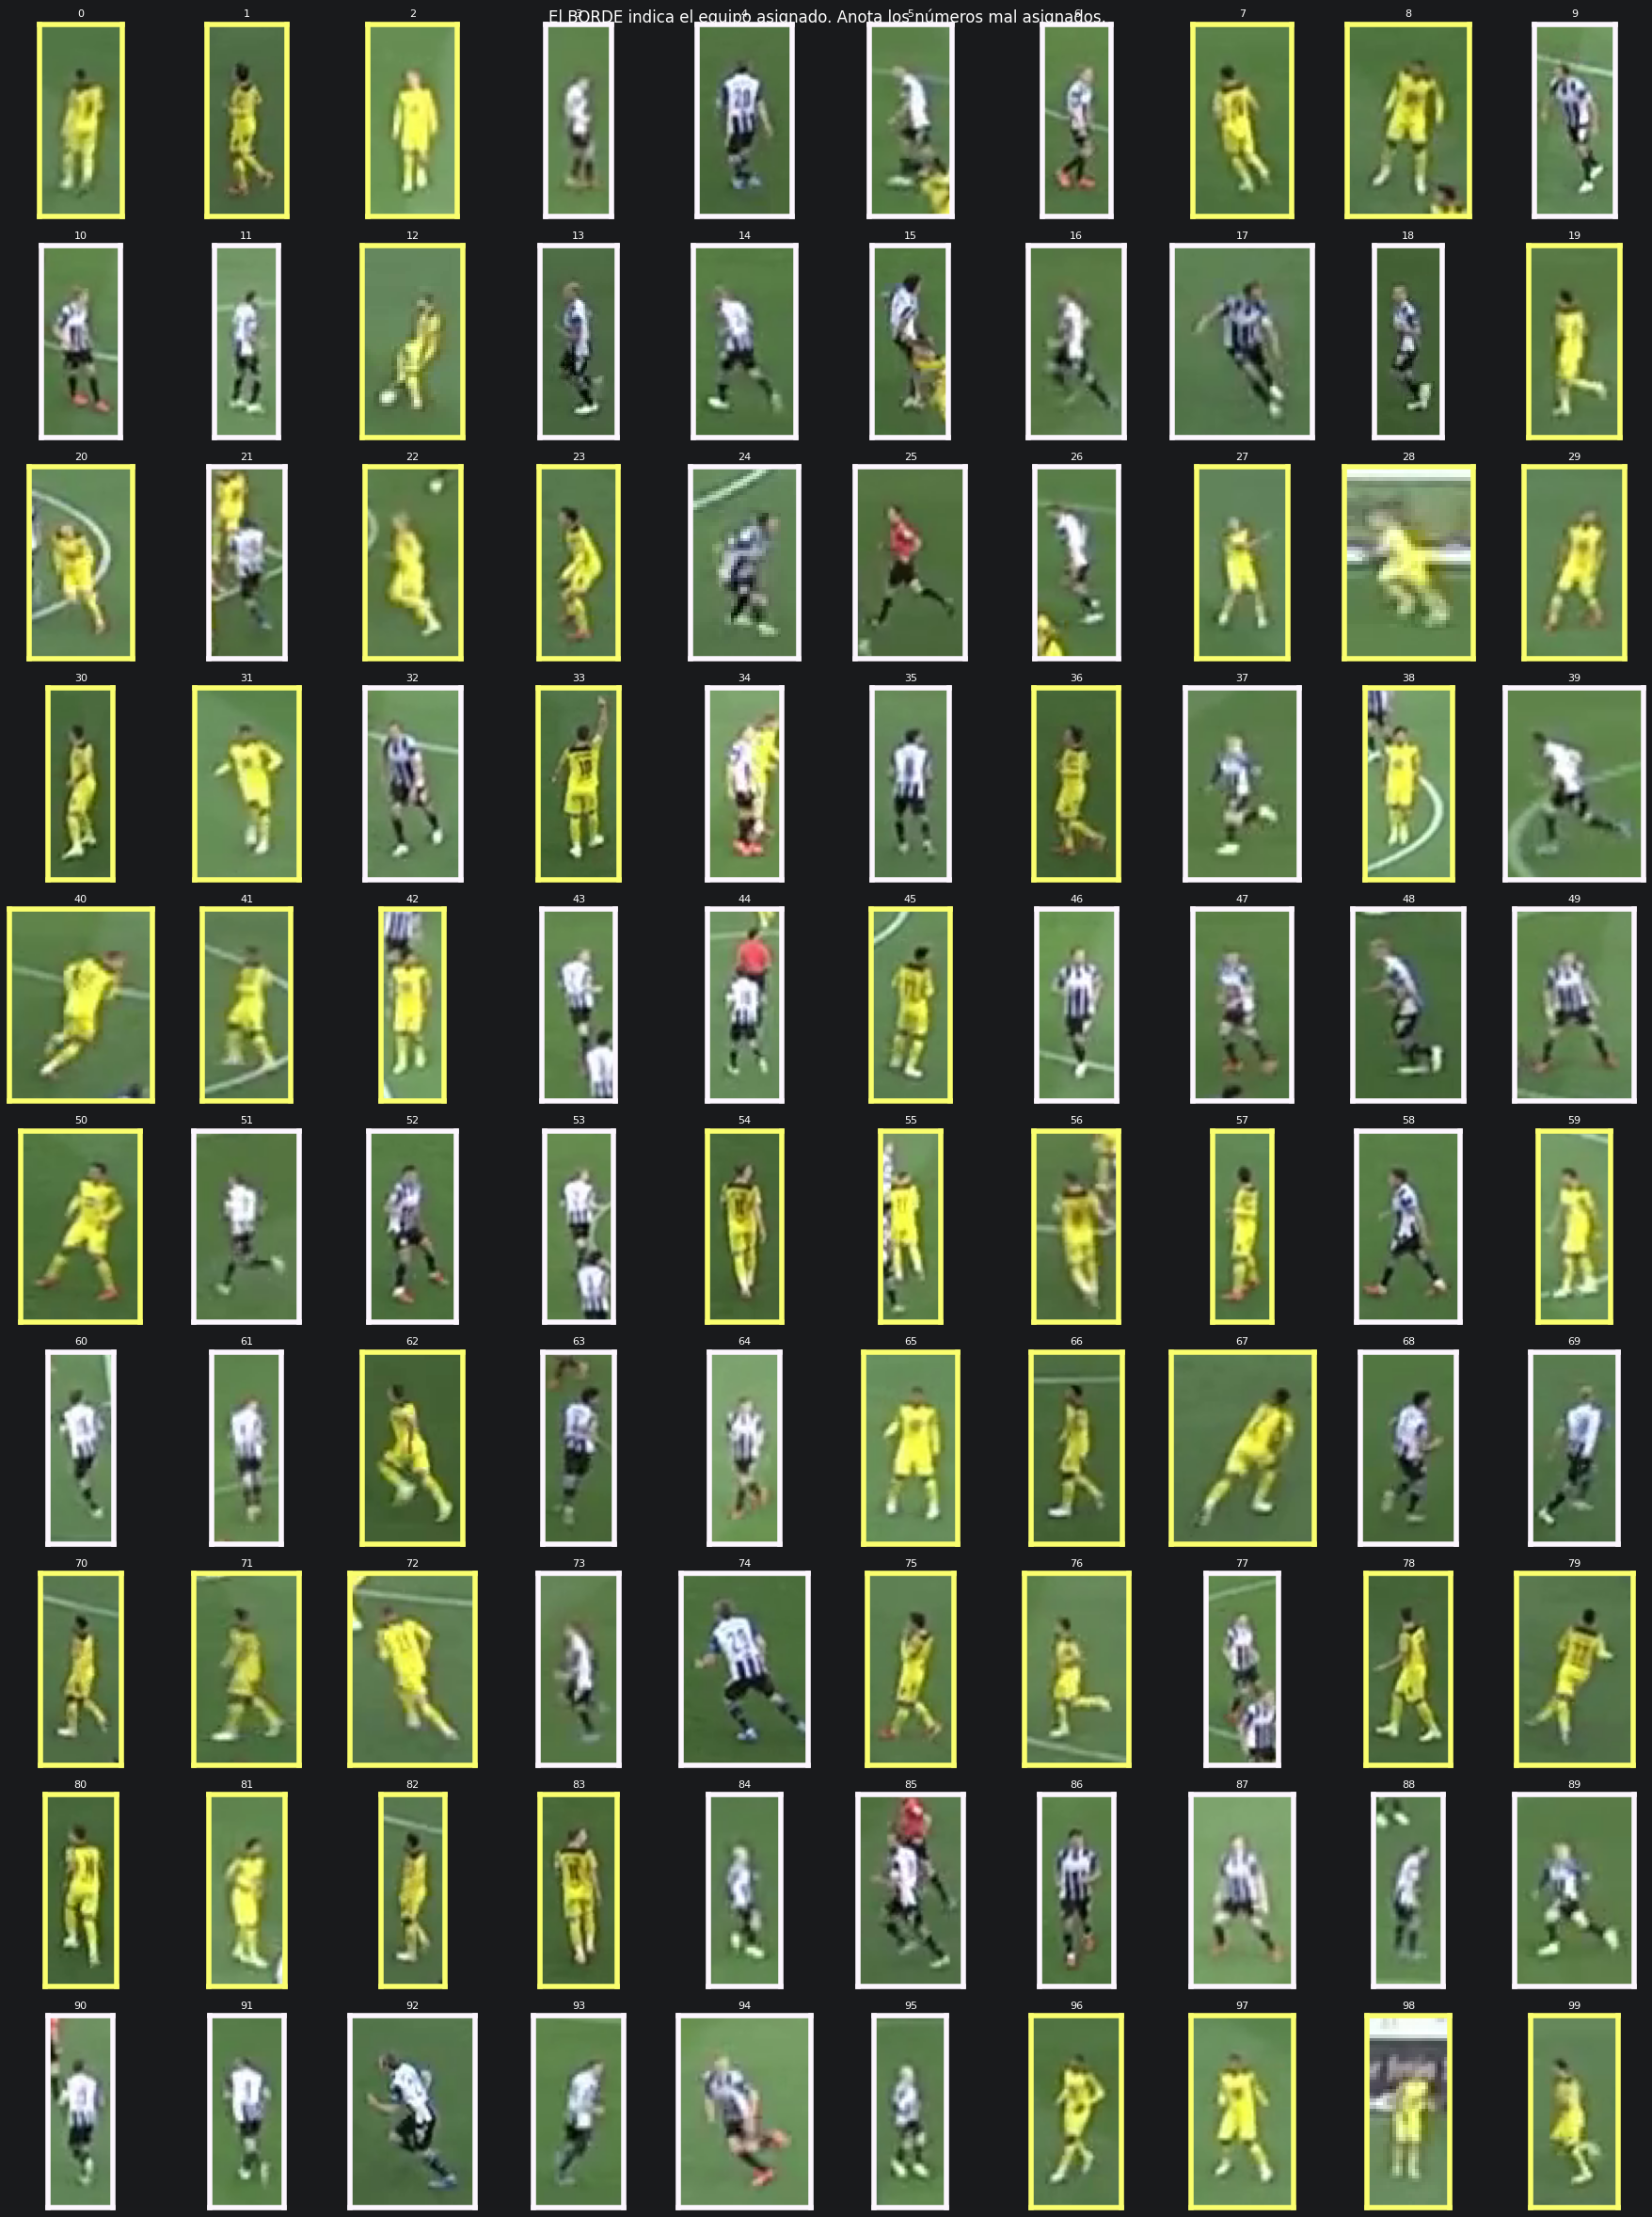

In [9]:
# Muestra aleatoria para validación manual
%matplotlib inline
import matplotlib.pyplot as plt

N_MUESTRA = 100
rng = np.random.default_rng(42)
candidatas = []
for f_idx, dets in enumerate(frames_track):
    for d in dets:
        if d["cls"] == 1 and equipo_det.get((f_idx, d["id"])) in (0, 1):
            candidatas.append((f_idx, d["id"], d["bbox"], equipo_det[(f_idx, d["id"])]))

idxs = rng.choice(len(candidatas), min(N_MUESTRA, len(candidatas)), replace=False)
muestra = [candidatas[i] for i in idxs]
frames_nec = sorted({m[0] for m in muestra})
imgs = {}
cap = cv2.VideoCapture(str(VIDEO_IN))
for f in frames_nec:
    cap.set(cv2.CAP_PROP_POS_FRAMES, f)
    ret, fr = cap.read()
    if ret:
        imgs[f] = fr
cap.release()

cols = 10
rows = (len(muestra) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(18, 2.4 * rows))
for ax in np.ravel(axes):
    ax.axis("off")
for k, (f, tid, bbox, eq) in enumerate(muestra):
    x1, y1, x2, y2 = [int(v) for v in bbox]
    mx, my = int(0.15 * (x2 - x1)) + 3, int(0.1 * (y2 - y1)) + 3
    crop = imgs[f][max(y1 - my, 0):y2 + my, max(x1 - mx, 0):x2 + mx]
    ax = np.ravel(axes)[k]
    if crop.size > 0:
        ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    b, g, r = np.array(color_equipo_bgr[eq]) / 255.0
    for spine in ax.spines.values():
        spine.set_visible(True); spine.set_color((r, g, b)); spine.set_linewidth(4)
    ax.set_xticks([]); ax.set_yticks([])
    ax.axis("on")
    ax.set_title(f"{k}", fontsize=8)

plt.suptitle("El BORDE indica el equipo asignado. Anota los números mal asignados.")
plt.tight_layout()
out_val = REPO_ROOT / "outputs" / f"validacion_equipos_{NOMBRE}.png"
plt.savefig(str(out_val), dpi=110, bbox_inches="tight")
print(f"Guardado: {out_val}")
plt.show()